# Evaluación Unidad 3 – Machine Learning
## Agrupación de pasajeros del Titanic con y sin PCA

**Asignatura:** Machine Learning
**Carrera:** Ingeniería Civil Industrial
**Institución:** Universidad Mayor
**Docente:** Franco Mansilla
**Integrantes:** Carolina Cid Jara y [nombres del grupo]

## Introducción

En este trabajo utilizaremos la base de datos Titanic, dando
continuidad a las actividades desarrolladas en las unidades 1 y 2.

Aplicaremos algoritmos de aprendizaje no supervisado para formar
grupos de pasajeros con características similares. Compararemos
los resultados utilizando los datos con y sin PCA.

Finalmente, evaluaremos los modelos y analizaremos si los grupos
encontrados se relacionan con la supervivencia de los pasajeros.

# 1. Preparación de los datos

Utilizaremos la base Titanic de las unidades anteriores.
Primero cargaremos los datos y revisaremos su estructura,
los valores faltantes y los registros duplicados.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Cargar la base de datos Titanic
datos = pd.read_csv("train (1).csv")

# Mostrar los primeros cinco pasajeros
datos.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1.1. Revisión inicial de los datos

Revisaremos la cantidad de pasajeros y variables, los valores
faltantes y los registros duplicados. Esto permitirá identificar
qué datos necesitan tratamiento antes de aplicar los modelos.

In [3]:
# Cantidad de filas y columnas
print("Cantidad de pasajeros:", datos.shape[0])
print("Cantidad de columnas:", datos.shape[1])

# Valores faltantes en cada columna
print("\nValores faltantes:")
print(datos.isnull().sum())

# Registros completamente duplicados
print("\nRegistros duplicados:", datos.duplicated().sum())

Cantidad de pasajeros: 891
Cantidad de columnas: 12

Valores faltantes:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Registros duplicados: 0


## 1.2. Tratamiento de valores faltantes

Reemplazaremos las edades faltantes por la mediana, porque es
menos sensible a valores extremos que el promedio.

Los puertos de embarque faltantes se reemplazarán por la categoría
más frecuente, ya que se trata de una variable categórica.

Eliminaremos Cabin porque aproximadamente el 77% de sus datos
están ausentes. Estas decisiones mantienen el criterio utilizado
en la Unidad 1.

In [4]:
# Crear una copia para conservar la base original
datos_limpios = datos.copy()

# Reemplazar edades faltantes por la mediana
mediana_edad = datos_limpios["Age"].median()
datos_limpios["Age"] = datos_limpios["Age"].fillna(mediana_edad)

# Reemplazar puertos faltantes por el más frecuente
puerto_frecuente = datos_limpios["Embarked"].mode()[0]
datos_limpios["Embarked"] = datos_limpios["Embarked"].fillna(
    puerto_frecuente
)

# Eliminar la columna Cabin
datos_limpios = datos_limpios.drop(columns=["Cabin"])

# Comprobar los resultados
print("Mediana de edad:", mediana_edad)
print("Puerto más frecuente:", puerto_frecuente)
print("\nValores faltantes después de la limpieza:")
print(datos_limpios.isnull().sum())

Mediana de edad: 28.0
Puerto más frecuente: S

Valores faltantes después de la limpieza:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


## 1.3. Selección de variables

Utilizaremos las mismas siete características de la Unidad 2:
clase del pasaje, sexo, edad, hermanos o cónyuges a bordo,
padres o hijos a bordo, tarifa y puerto de embarque.

Excluiremos PassengerId, Name y Ticket porque son identificadores
o contienen muchas categorías distintas.

La variable Survived se guardará por separado. No se utilizará
para formar los grupos, sino para comprobar posteriormente
si estos se relacionan con la supervivencia.

In [5]:
# Características utilizadas para formar los grupos
variables = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked"
]

X = datos_limpios[variables].copy()

# Guardar la supervivencia para la evaluación posterior
y = datos_limpios["Survived"].copy()

# Revisar las características seleccionadas
print("Dimensiones de X:", X.shape)
print("Cantidad de valores en y:", len(y))

X.head()

Dimensiones de X: (891, 7)
Cantidad de valores en y: 891


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


## 1.4. Codificación de variables categóricas

Las variables Sex y Embarked contienen categorías expresadas
como texto. Aplicaremos One Hot Encoding para convertir cada
categoría en una columna de ceros y unos.

Esto permite calcular distancias entre pasajeros sin asignar
un orden artificial a las categorías. Conservaremos todas las
categorías para mantener una comparación simétrica entre ellas.

In [6]:
# Convertir sexo y puerto en columnas de ceros y unos
X_codificado = pd.get_dummies(
    X,
    columns=["Sex", "Embarked"],
    drop_first=False,
    dtype=int
)

# Revisar el resultado
print("Dimensiones después de codificar:", X_codificado.shape)

X_codificado.head()

Dimensiones después de codificar: (891, 10)


,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0
2,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1
4,3,35.0,0,0,8.0500,0,1,0,0,1


## 1.5. Estandarización de variables numéricas

Las variables numéricas tienen distintas escalas. Por ejemplo,
la edad se expresa en años y la tarifa en unidades monetarias.
Estas diferencias pueden afectar las distancias entre pasajeros.

Aplicaremos StandardScaler a Pclass, Age, SibSp, Parch y Fare.
Esta transformación resta la media y divide por la desviación
estándar, evitando que una variable domine solo por su escala.

Los indicadores de sexo y puerto se conservarán como ceros y unos.
Pclass se tratará como una variable ordinal, manteniendo el
criterio utilizado en la Unidad 2.

In [7]:
from sklearn.preprocessing import StandardScaler

# Columnas numéricas que vamos a estandarizar
variables_numericas = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

# Conservar una copia y transformar solo estas columnas
X_preparado = X_codificado.copy()

escalador = StandardScaler()

X_preparado[variables_numericas] = escalador.fit_transform(
    X_codificado[variables_numericas]
)

# Comprobar la preparación
print("Dimensiones finales:", X_preparado.shape)
print("Valores faltantes:", X_preparado.isnull().sum().sum())

X_preparado.head()

Dimensiones finales: (891, 10)
Valores faltantes: 0


,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0.827377,-0.565736,0.432793,-0.473674,-0.502445,0,1,0,0,1
1,-1.566107,0.663861,0.432793,-0.473674,0.786845,1,0,1,0,0
2,0.827377,-0.258337,-0.474545,-0.473674,-0.488854,1,0,0,0,1
3,-1.566107,0.433312,0.432793,-0.473674,0.420730,1,0,0,0,1
4,0.827377,0.433312,-0.474545,-0.473674,-0.486337,0,1,0,0,1


# 2. Experimento con y sin PCA

PCA permite resumir las características de los pasajeros en
nuevas variables llamadas componentes principales.

Compararemos dos versiones de la base: una con las 10 columnas
preparadas y otra reducida mediante PCA.

Seleccionaremos el menor número de componentes que conserve
al menos el 90% de la varianza. Este criterio busca reducir
la cantidad de columnas manteniendo la mayor parte de la
variación de los datos.

PCA no utilizará la variable Survived. Conservar varianza no
garantiza separar correctamente la supervivencia.

In [8]:
from sklearn.decomposition import PCA

# Analizar todos los componentes posibles
pca_completo = PCA(svd_solver="full")
pca_completo.fit(X_preparado)

# Calcular la varianza acumulada
varianza_acumulada = np.cumsum(
    pca_completo.explained_variance_ratio_
)

# Encontrar el mínimo de componentes que conserve al menos 90%
n_componentes = int(
    np.searchsorted(varianza_acumulada, 0.90) + 1
)

# Mostrar cuánto conserva cada componente
tabla_varianza = pd.DataFrame({
    "Componente": np.arange(1, len(varianza_acumulada) + 1),
    "Varianza individual (%)":
        pca_completo.explained_variance_ratio_ * 100,
    "Varianza acumulada (%)": varianza_acumulada * 100
})

print("Número mínimo de componentes:", n_componentes)
display(tabla_varianza.round(2))

Número mínimo de componentes: 6


,Componente,Varianza individual (%),Varianza acumulada (%)
0,1,29.35,29.35
1,2,28.20,57.55
2,3,12.50,70.05
3,4,10.14,80.19
4,5,6.90,87.10
5,6,6.54,93.63
6,7,4.70,98.34
7,8,1.66,100.00
8,9,0.00,100.00
9,10,0.00,100.00


Dimensiones sin PCA: (891, 10)
Dimensiones con PCA: (891, 6)
Varianza conservada: 93.63 %


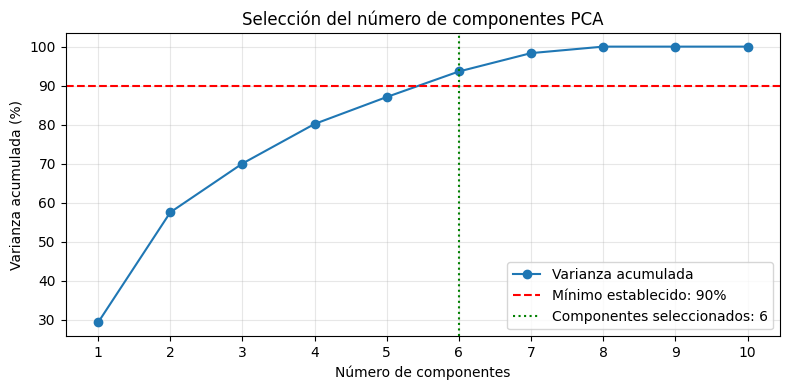

In [9]:
# Versión sin PCA: conservar las 10 columnas preparadas
X_sin_pca = X_preparado.copy()

# Versión con PCA: utilizar el número seleccionado de componentes
pca = PCA(n_components=n_componentes, svd_solver="full")
X_con_pca = pca.fit_transform(X_preparado)

print("Dimensiones sin PCA:", X_sin_pca.shape)
print("Dimensiones con PCA:", X_con_pca.shape)

print(
    "Varianza conservada:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# Gráfico de varianza acumulada
plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(1, len(varianza_acumulada) + 1),
    varianza_acumulada * 100,
    marker="o",
    label="Varianza acumulada"
)

plt.axhline(
    y=90,
    color="red",
    linestyle="--",
    label="Mínimo establecido: 90%"
)

plt.axvline(
    x=n_componentes,
    color="green",
    linestyle=":",
    label=f"Componentes seleccionados: {n_componentes}"
)

plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada (%)")
plt.title("Selección del número de componentes PCA")
plt.xticks(np.arange(1, len(varianza_acumulada) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.1. Interpretación del resultado de PCA

Se seleccionaron seis componentes porque es el menor número
que permite conservar al menos el 90% de la varianza.
Estos componentes conservan aproximadamente el 93,63%.

La base pasó de 10 columnas a 6 componentes, manteniendo
los mismos 891 pasajeros.

Utilizaremos ambas versiones para comprobar si la reducción
de dimensiones mejora o empeora los resultados del clustering.

# 3. Comparación de algoritmos de clustering

Aplicaremos cinco algoritmos a la base con PCA y sin PCA,
obteniendo diez experimentos.

Utilizaremos tres algoritmos basados en distancia:

- K-Means: agrupa pasajeros alrededor de centros cercanos.
- Clustering jerárquico Ward: une progresivamente grupos,
  buscando reducir el aumento de la variación interna.
- Birch: crea pequeños resúmenes de los datos y luego los agrupa.

También utilizaremos dos algoritmos basados en densidad:

- DBSCAN: identifica grupos de pasajeros con suficientes
  vecinos cercanos y puede dejar observaciones como ruido.
- OPTICS: analiza la conectividad entre pasajeros para
  identificar agrupaciones según su densidad.

Esta selección permite comparar distintas formas de agrupar
a los mismos pasajeros.

In [10]:
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    Birch,
    DBSCAN,
    OPTICS
)

# Esta función crea cinco modelos nuevos cada vez que se utiliza
def crear_modelos():
    return {
        "K-Means": KMeans(
            n_clusters=2,
            n_init=20,
            random_state=42
        ),

        "Jerárquico Ward": AgglomerativeClustering(
            n_clusters=2,
            linkage="ward"
        ),

        "Birch": Birch(
            threshold=0.5,
            n_clusters=2
        ),

        "DBSCAN": DBSCAN(
            eps=1.2,
            min_samples=10
        ),

        "OPTICS": OPTICS(
            min_samples=10,
            xi=0.05,
            min_cluster_size=0.05
        )
    }

print("Algoritmos preparados:")
for nombre in crear_modelos():
    print("-", nombre)

Algoritmos preparados:
- K-Means
- Jerárquico Ward
- Birch
- DBSCAN
- OPTICS


## 3.1. Justificación de los parámetros

En K-Means, Ward y Birch fijamos dos grupos como contraste
inicial con la variable binaria de supervivencia. Esto no
significa que los grupos deban coincidir con ella.

En DBSCAN utilizamos un radio de vecindad de 1,2 y un mínimo
de 10 observaciones para identificar zonas densas.

En OPTICS utilizamos min_samples=10, xi=0,05 y un tamaño
mínimo de grupo equivalente al 5% de los pasajeros.

Estos parámetros constituyen una comparación exploratoria;
no afirmamos que sean los mejores posibles. Los mantendremos
en ambas versiones, considerando que PCA modifica las distancias.
La supervivencia no se utilizará para ajustar los modelos.

In [11]:
# Las dos versiones que vamos a comparar
bases = {
    "Sin PCA": X_sin_pca.to_numpy(),
    "Con PCA": X_con_pca
}

# Guardar los grupos asignados y el resumen de cada experimento
etiquetas_modelos = {}
resumen_modelos = []

for version, base in bases.items():
    for nombre, modelo in crear_modelos().items():

        # Ajustar el modelo y obtener el grupo de cada pasajero
        etiquetas = modelo.fit_predict(base)

        etiquetas_modelos[(version, nombre)] = etiquetas

        # La etiqueta -1 corresponde a ruido
        asignados = etiquetas != -1

        cantidad_grupos = len(
            np.unique(etiquetas[asignados])
        )

        cantidad_ruido = int((~asignados).sum())
        cobertura = asignados.mean() * 100

        resumen_modelos.append({
            "Versión": version,
            "Modelo": nombre,
            "Grupos": cantidad_grupos,
            "Pasajeros de ruido": cantidad_ruido,
            "Cobertura (%)": cobertura
        })

tabla_resumen = pd.DataFrame(resumen_modelos)

display(tabla_resumen.round(2))

/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_optics.py:1086: RuntimeWarning: divide by zero encountered in divide
  ratio = reachability_plot[:-1] / reachability_plot[1:]
/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_optics.py:1086: RuntimeWarning: divide by zero encountered in divide
  ratio = reachability_plot[:-1] / reachability_plot[1:]


,Versión,Modelo,Grupos,Pasajeros de ruido,Cobertura (%)
0,Sin PCA,K-Means,2,0,100.00
1,Sin PCA,Jerárquico Ward,2,0,100.00
2,Sin PCA,Birch,2,0,100.00
3,Sin PCA,DBSCAN,9,264,70.37
4,Sin PCA,OPTICS,3,621,30.30
5,Con PCA,K-Means,2,0,100.00
6,Con PCA,Jerárquico Ward,2,0,100.00
7,Con PCA,Birch,2,0,100.00
8,Con PCA,DBSCAN,3,160,82.04
9,Con PCA,OPTICS,7,393,55.89


# 4. Evaluación de los modelos

Utilizaremos tres métricas para comparar las agrupaciones:

- Silhouette: evalúa si los pasajeros se parecen más a su
  propio grupo que a los otros. Un valor más alto es mejor.

- Davies-Bouldin: compara la dispersión y separación de los
  grupos. Un valor más bajo es mejor.

- Calinski-Harabasz: relaciona la separación entre grupos
  con la variación interna. Un valor más alto es preferible,
  considerando también las dimensiones y cantidad de grupos.

En los modelos de densidad excluiremos el ruido del cálculo
y revisaremos la cobertura para interpretar los resultados.

Estas métricas requieren al menos dos grupos y menos grupos
que pasajeros evaluados. Si no se cumple, mostraremos NaN,
que significa que la métrica no puede calcularse.

In [12]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

resultados_metricas = []

for (version, nombre), etiquetas in etiquetas_modelos.items():

    base = bases[version]

    # Evaluar únicamente pasajeros asignados a un grupo
    asignados = etiquetas != -1
    datos_evaluados = base[asignados]
    grupos_evaluados = etiquetas[asignados]

    cantidad_grupos = len(np.unique(grupos_evaluados))

    # Valores por defecto si las métricas no se pueden calcular
    silhouette = np.nan
    davies = np.nan
    calinski = np.nan

    if 2 <= cantidad_grupos < len(datos_evaluados):

        silhouette = silhouette_score(
            datos_evaluados, grupos_evaluados
        )

        davies = davies_bouldin_score(
            datos_evaluados, grupos_evaluados
        )

        calinski = calinski_harabasz_score(
            datos_evaluados, grupos_evaluados
        )

    resultados_metricas.append({
        "Versión": version,
        "Modelo": nombre,
        "Grupos": cantidad_grupos,
        "Cobertura (%)": asignados.mean() * 100,
        "Silhouette": silhouette,
        "Davies-Bouldin": davies,
        "Calinski-Harabasz": calinski
    })

tabla_metricas = pd.DataFrame(resultados_metricas)

display(tabla_metricas.round(3))

,Versión,Modelo,Grupos,Cobertura (%),Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Sin PCA,K-Means,2,100.000,0.305,1.532,248.988
1,Sin PCA,Jerárquico Ward,2,100.000,0.222,1.834,195.940
2,Sin PCA,Birch,2,100.000,0.458,1.082,126.725
3,Sin PCA,DBSCAN,9,70.370,0.241,1.221,74.741
4,Sin PCA,OPTICS,3,30.303,0.579,0.774,434.924
5,Con PCA,K-Means,2,100.000,0.329,1.444,270.437
6,Con PCA,Jerárquico Ward,2,100.000,0.270,1.602,238.388
7,Con PCA,Birch,2,100.000,0.266,1.695,219.921
8,Con PCA,DBSCAN,3,82.043,0.327,0.736,43.512
9,Con PCA,OPTICS,7,55.892,0.419,0.958,314.965


## 4.1. Selección del modelo

Consideraremos los modelos que tengan métricas válidas
y una cobertura de al menos el 80% de los pasajeros.

Entre ellos seleccionaremos el mayor Silhouette. En caso
de empate, preferiremos el menor Davies-Bouldin.

El mínimo de cobertura evita elegir una agrupación que
incluya solo una pequeña parte de la base.

Esta elección es exploratoria: las métricas calculadas en
distintas dimensiones o sobre distintos pasajeros no son
perfectamente comparables. La variable Survived no se utiliza
para seleccionar el modelo.

In [13]:
# Filtrar los modelos que cumplen el criterio
modelos_elegibles = tabla_metricas[
    (tabla_metricas["Cobertura (%)"] >= 80)
    & tabla_metricas["Silhouette"].notna()
].copy()

# Ordenar: mayor Silhouette y, en caso de empate, menor Davies-Bouldin
modelos_ordenados = modelos_elegibles.sort_values(
    by=["Silhouette", "Davies-Bouldin"],
    ascending=[False, True]
)

if modelos_ordenados.empty:
    raise ValueError("Ningún modelo cumple los criterios establecidos.")

# Guardar el modelo seleccionado y sus grupos
mejor_modelo = modelos_ordenados.iloc[0]

version_elegida = mejor_modelo["Versión"]
nombre_elegido = mejor_modelo["Modelo"]

grupos_finales = etiquetas_modelos[
    (version_elegida, nombre_elegido)
]

print("Modelo seleccionado:", nombre_elegido)
print("Versión seleccionada:", version_elegida)

display(mejor_modelo.to_frame("Resultado"))

Modelo seleccionado: Birch
Versión seleccionada: Sin PCA


,Resultado
Versión,Sin PCA
Modelo,Birch
Grupos,2
Cobertura (%),100.0
Silhouette,0.45825
Davies-Bouldin,1.082485
Calinski-Harabasz,126.724583


## 4.2. Comparación de los grupos con la supervivencia

Utilizaremos la variable Survived, reservada desde el inicio,
para comprobar cómo se distribuye la supervivencia en cada grupo.

Survived = 0 indica que el pasajero no sobrevivió.
Survived = 1 indica que sobrevivió.

Los números de los grupos son etiquetas arbitrarias:
el grupo 0 no significa necesariamente que no sobrevivió.

Calcularemos ARI y NMI para comparar ambas agrupaciones.
ARI corrige la coincidencia esperable por azar; un valor
cercano a 0 indica poca coincidencia adicional al azar.
NMI mide información compartida y va de 0 a 1.
En ambas métricas, 1 representa coincidencia perfecta.

In [14]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Comparar los grupos encontrados con la supervivencia real
ari = adjusted_rand_score(y, grupos_finales)
nmi = normalized_mutual_info_score(y, grupos_finales)

print("ARI:", round(ari, 3))
print("NMI:", round(nmi, 3))

# Contar sobrevivientes y no sobrevivientes en cada grupo
tabla_supervivencia = pd.crosstab(
    grupos_finales,
    y.to_numpy(),
    rownames=["Grupo"],
    colnames=["Survived"]
)

print("\nCantidad de pasajeros por grupo y supervivencia:")
display(tabla_supervivencia)

# Calcular porcentajes dentro de cada grupo
porcentajes_supervivencia = tabla_supervivencia.div(
    tabla_supervivencia.sum(axis=1),
    axis=0
) * 100

print("\nPorcentajes dentro de cada grupo:")
display(porcentajes_supervivencia.round(2))

ARI: 0.03
NMI: 0.028

Cantidad de pasajeros por grupo y supervivencia:


Survived,0,1
Grupo,,
0,540,315
1,9,27



Porcentajes dentro de cada grupo:


Survived,0,1
Grupo,,
0,63.16,36.84
1,25.00,75.00


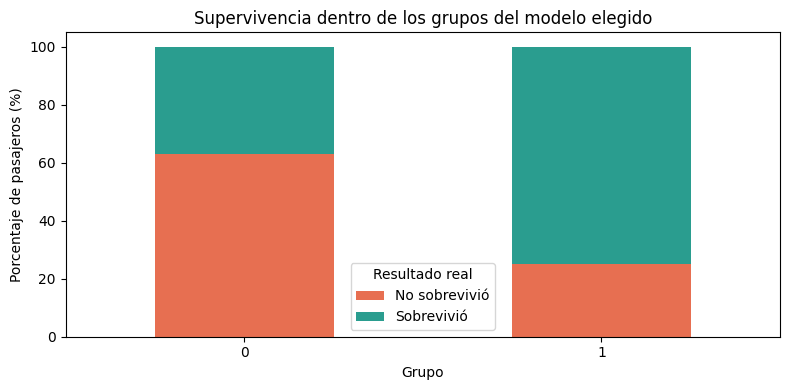

In [15]:
# Mostrar la distribución de supervivencia dentro de cada grupo
porcentajes_supervivencia.rename(
    columns={0: "No sobrevivió", 1: "Sobrevivió"}
).plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4),
    color=["#e76f51", "#2a9d8f"]
)

plt.title("Supervivencia dentro de los grupos del modelo elegido")
plt.xlabel("Grupo")
plt.ylabel("Porcentaje de pasajeros (%)")
plt.xticks(rotation=0)
plt.legend(title="Resultado real")
plt.tight_layout()
plt.show()

## 4.3. Interpretación de la relación con la supervivencia

En la ejecución realizada, Birch sin PCA formó dos grupos:

- Grupo 0: 855 pasajeros. Sobrevivieron 315, equivalentes
  al 36,84% del grupo.
- Grupo 1: 36 pasajeros. Sobrevivieron 27, equivalentes
  al 75% del grupo.

Aunque el grupo 1 presenta mayor proporción de supervivencia,
ambos grupos contienen sobrevivientes y no sobrevivientes.

Los resultados ARI = 0,030 y NMI = 0,028 muestran poca
coincidencia entre los grupos encontrados y las clases reales.

Por lo tanto, el modelo no reconstruye adecuadamente las
clases de supervivencia. Una buena separación según las
características de los pasajeros no garantiza distinguir
correctamente quién sobrevivió.

In [16]:
# Reunir características originales y grupos encontrados
perfil_pasajeros = X.copy()
perfil_pasajeros["Grupo"] = grupos_finales

# Promedios de las variables numéricas por grupo
perfil_numerico = perfil_pasajeros.groupby(
    "Grupo"
)[variables_numericas].mean()

print("Características promedio por grupo:")
display(perfil_numerico.round(2))

# Porcentaje de cada sexo dentro de los grupos
perfil_sexo = pd.crosstab(
    perfil_pasajeros["Grupo"],
    perfil_pasajeros["Sex"],
    normalize="index"
) * 100

print("\nDistribución de sexo por grupo (%):")
display(perfil_sexo.round(2))

# Comprobar la distribución de clases del pasaje
perfil_clase = pd.crosstab(
    perfil_pasajeros["Grupo"],
    perfil_pasajeros["Pclass"],
    normalize="index"
) * 100

print("\nDistribución de clases por grupo (%):")
display(perfil_clase.round(2))

Características promedio por grupo:


,Pclass,Age,SibSp,Parch,Fare
Grupo,,,,,
0,2.36,29.35,0.52,0.35,24.48
1,1.00,29.72,0.64,1.22,215.75



Distribución de sexo por grupo (%):


Sex,female,male
Grupo,,
0,34.15,65.85
1,61.11,38.89



Distribución de clases por grupo (%):


Pclass,1,2,3
Grupo,,,
0,21.05,21.52,57.43
1,100.00,0.00,0.00


## 4.4. Características de los grupos encontrados

El grupo 1 contiene pasajeros de primera clase y presenta
una tarifa promedio de aproximadamente 215,75. En el grupo 0,
la tarifa promedio es aproximadamente 24,48.

Las edades promedio son similares: alrededor de 30 años.
El porcentaje de mujeres es mayor en el grupo 1:
aproximadamente 61,11%, frente al 34,15% del grupo 0.

Estos resultados sugieren que Birch separó un pequeño grupo
de pasajeros con características socioeconómicas diferentes,
principalmente por clase y tarifa.

Los grupos tienen tamaños muy desiguales: 855 y 36 pasajeros.
Esta diferencia y las tarifas altas deben considerarse al
interpretar el Silhouette obtenido.

La mayor supervivencia del grupo 1 es una asociación observada;
no demuestra que pagar una tarifa mayor haya causado sobrevivir.

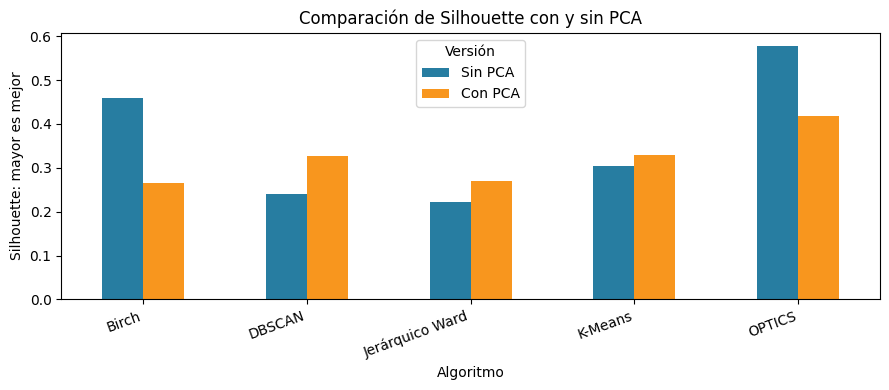

In [17]:
# Organizar Silhouette por modelo y versión
comparacion_pca = tabla_metricas.pivot(
    index="Modelo",
    columns="Versión",
    values="Silhouette"
)

# Mantener el mismo orden de las versiones
comparacion_pca = comparacion_pca[["Sin PCA", "Con PCA"]]

comparacion_pca.plot(
    kind="bar",
    figsize=(9, 4),
    color=["#277da1", "#f8961e"]
)

plt.title("Comparación de Silhouette con y sin PCA")
plt.xlabel("Algoritmo")
plt.ylabel("Silhouette: mayor es mejor")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Versión")
plt.tight_layout()
plt.show()

## 4.5. Comparación de resultados con y sin PCA

PCA no mejoró todos los algoritmos de la misma manera.

En K-Means, Silhouette aumentó aproximadamente de 0,305
a 0,329. En el modelo jerárquico Ward aumentó de 0,222
a 0,270. En Birch disminuyó de 0,458 a 0,266.

DBSCAN aumentó su cobertura de 70,37% a 82,04% al aplicar
PCA, por lo que más pasajeros quedaron asignados a grupos.

OPTICS sin PCA obtuvo un Silhouette aproximado de 0,579,
pero su cobertura fue solo 30,30%. Por eso no fue elegido,
aunque su Silhouette fuera el más alto.

El gráfico incluye todos los experimentos. Las métricas de
densidad excluyen el ruido, por lo que deben interpretarse
junto con la cobertura de cada modelo.

Concluimos que reducir dimensiones puede mejorar algunos
resultados y empeorar otros. En este experimento, Birch
sin PCA fue seleccionado según la regla establecida.

## 4.5. Comparación de resultados con y sin PCA

PCA no mejoró todos los algoritmos de la misma manera.

En K-Means, Silhouette aumentó aproximadamente de 0,305
a 0,329. En el modelo jerárquico Ward aumentó de 0,222
a 0,270. En Birch disminuyó de 0,458 a 0,266.

DBSCAN aumentó su cobertura de 70,37% a 82,04% al aplicar
PCA, por lo que más pasajeros quedaron asignados a grupos.

OPTICS sin PCA obtuvo un Silhouette aproximado de 0,579,
pero su cobertura fue solo 30,30%. Por eso no fue elegido,
aunque su Silhouette fuera el más alto.

El gráfico incluye todos los experimentos. Las métricas de
densidad excluyen el ruido, por lo que deben interpretarse
junto con la cobertura de cada modelo.

Concluimos que reducir dimensiones puede mejorar algunos
resultados y empeorar otros. En este experimento, Birch
sin PCA fue seleccionado según la regla establecida.

# Conclusión

En este trabajo utilizamos la base Titanic de las unidades
anteriores. Tratamos los valores faltantes, seleccionamos
las características, codificamos las categorías y
estandarizamos las variables numéricas.

Aplicamos PCA y seleccionamos seis componentes, que conservaron
aproximadamente el 93,63% de la varianza. Comparamos cinco
algoritmos con y sin PCA, realizando diez experimentos.

Según la regla de cobertura mínima del 80% y mayor Silhouette,
seleccionamos Birch sin PCA. Este modelo agrupó a todos los
pasajeros, aunque formó grupos de tamaños muy diferentes.

Al comparar los grupos con la supervivencia, obtuvimos
ARI de 0,030 y NMI de 0,028. Estos resultados indican que
los grupos no reproducen adecuadamente las clases de
sobrevivientes y no sobrevivientes.

El grupo pequeño presentó principalmente pasajeros de
primera clase y tarifas altas. Por lo tanto, el modelo
identificó un perfil de pasajeros, pero no separó
correctamente la supervivencia.

Concluimos que PCA no mejora todos los algoritmos y que
una buena separación de grupos no garantiza coincidencia
con una variable objetivo conocida.

Como limitaciones, utilizamos una configuración por algoritmo
y observamos sensibilidad a las tarifas altas. En futuros
análisis podrían compararse otros parámetros y evaluarse
la estabilidad de los grupos.

# Referencias

- Kaggle. Titanic: Machine Learning from Disaster.
  https://www.kaggle.com/competitions/titanic

- Scikit-learn. Documentación de clustering y sus métricas.
  https://scikit-learn.org/stable/modules/clustering.html

- Scikit-learn. Documentación de PCA.
  https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

- Scikit-learn. Documentación de preprocesamiento de datos.
  https://scikit-learn.org/stable/modules/preprocessing.html

